In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.stats.power import zt_ind_solve_power, NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

print("Библиотеки загружены")

Библиотеки загружены


In [2]:
# Параметры для Power Analysis
baseline_ret7 = 0.19      # текущий retention_7 (~19%)
baseline_ret1 = 0.45      # текущий retention_1 (~45%)

alpha = 0.05              # уровень значимости
power = 0.80              # мощность

# MDE — минимальный эффект, который хотим заметить
# Вариант 1: относительный (например, +5% от baseline)
mde_relative = 0.05
mde_abs_ret7 = baseline_ret7 * mde_relative   # 0.19 * 0.05 = 0.0095
mde_abs_ret1 = baseline_ret1 * mde_relative

print(f"Baseline retention_7: {baseline_ret7:.2%}")
print(f"Baseline retention_1: {baseline_ret1:.2%}")
print()
print(f"MDE (относительный): {mde_relative:.1%}")
print(f"MDE (абсолютный) для ret7: {mde_abs_ret7:.4f}")
print(f"MDE (абсолютный) для ret1: {mde_abs_ret1:.4f}")

Baseline retention_7: 19.00%
Baseline retention_1: 45.00%

MDE (относительный): 5.0%
MDE (абсолютный) для ret7: 0.0095
MDE (абсолютный) для ret1: 0.0225


# нужный размер выборки для retention_7

In [3]:
# Размер эффекта (Cohen's h для пропорций)
effect_size_ret7 = proportion_effectsize(baseline_ret7, baseline_ret7 + mde_abs_ret7)

print(f"Effect size (Cohen's h) для ret7: {effect_size_ret7:.4f}")
print()

# Нужный размер выборки на группу
n_required_ret7 = zt_ind_solve_power(
    effect_size=effect_size_ret7,
    alpha=alpha,
    power=power,
    alternative='two-sided'
)

print(f"Нужно пользователей на группу (ret7): {int(np.ceil(n_required_ret7)):,}")
print(f"Всего на две группы: {int(np.ceil(n_required_ret7 * 2)):,}")

Effect size (Cohen's h) для ret7: -0.0240

Нужно пользователей на группу (ret7): 27,274
Всего на две группы: 54,547


# То же для retention_1

In [4]:
effect_size_ret1 = proportion_effectsize(baseline_ret1, baseline_ret1 + mde_abs_ret1)

n_required_ret1 = zt_ind_solve_power(
    effect_size=effect_size_ret1,
    alpha=alpha,
    power=power,
    alternative='two-sided'
)

print(f"Effect size (Cohen's h) для ret1: {effect_size_ret1:.4f}")
print(f"Нужно пользователей на группу (ret1): {int(np.ceil(n_required_ret1)):,}")
print(f"Всего на две группы: {int(np.ceil(n_required_ret1 * 2)):,}")

Effect size (Cohen's h) для ret1: -0.0451
Нужно пользователей на группу (ret1): 7,705
Всего на две группы: 15,409


# Сравнение с фактическим размером групп

In [5]:
# Фактический размер групп
n_gate_30 = 44700
n_gate_40 = 45489
n_actual = min(n_gate_30, n_gate_40)

print(f"Фактический размер меньшей группы: {n_actual:,}")
print()

# Для ret7
print("=== Retention 7 ===")
print(f"Нужно: {int(np.ceil(n_required_ret7)):,}")
print(f"Есть:  {n_actual:,}")
if n_actual >= n_required_ret7:
    print("✅ Данных достаточно для MDE +5%")
else:
    print(f"❌ Данных НЕ достаточно. Не хватает: {int(n_required_ret7 - n_actual):,}")
print()

# Для ret1
print("=== Retention 1 ===")
print(f"Нужно: {int(np.ceil(n_required_ret1)):,}")
print(f"Есть:  {n_actual:,}")
if n_actual >= n_required_ret1:
    print("✅ Данных достаточно для MDE +5%")
else:
    print(f"❌ Данных НЕ достаточно. Не хватает: {int(n_required_ret1 - n_actual):,}")

Фактический размер меньшей группы: 44,700

=== Retention 7 ===
Нужно: 27,274
Есть:  44,700
✅ Данных достаточно для MDE +5%

=== Retention 1 ===
Нужно: 7,705
Есть:  44,700
✅ Данных достаточно для MDE +5%


In [6]:
# MDE = 10%
mde_rel_10 = 0.10
mde_abs_ret7_10 = baseline_ret7 * mde_rel_10

effect_size_10 = proportion_effectsize(baseline_ret7, baseline_ret7 + mde_abs_ret7_10)
n_required_10 = zt_ind_solve_power(
    effect_size=effect_size_10,
    alpha=alpha,
    power=power,
    alternative='two-sided'
)

print(f"MDE = 10% (для ret7)")
print(f"Нужно пользователей на группу: {int(np.ceil(n_required_10)):,}")
print(f"Фактически есть: {n_actual:,}")
print()

if n_actual >= n_required_10:
    print("✅ Данных достаточно для MDE +10%")
else:
    print(f"❌ Не хватает: {int(n_required_10 - n_actual):,}")

MDE = 10% (для ret7)
Нужно пользователей на группу: 6,941
Фактически есть: 44,700

✅ Данных достаточно для MDE +10%


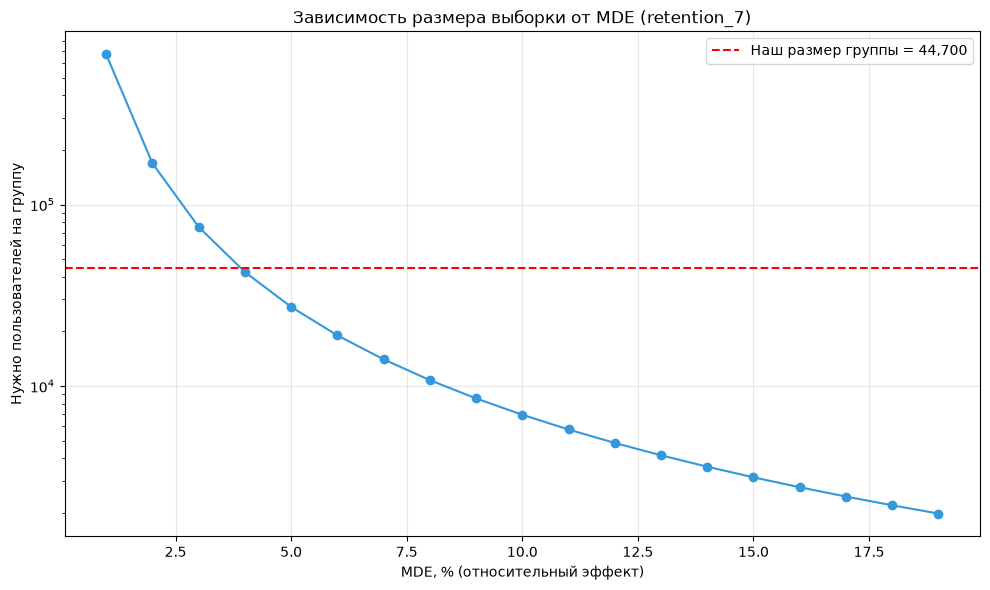

Сохранено: 04_power_analysis.png


In [8]:
# Считаем размер выборки для разных MDE
mde_range = np.arange(0.01, 0.20, 0.01)  # от 1% до 20%
n_required_range = []

for mde in mde_range:
    mde_abs = baseline_ret7 * mde
    es = proportion_effectsize(baseline_ret7, baseline_ret7 + mde_abs)
    n = zt_ind_solve_power(effect_size=es, alpha=alpha, power=power, alternative='two-sided')
    n_required_range.append(n)

# Визуализация
plt.figure(figsize=(10, 6))
plt.plot(mde_range * 100, n_required_range, marker='o', color='#3498db')
plt.axhline(y=n_actual, color='red', linestyle='--', label=f'Наш размер группы = {n_actual:,}')
plt.xlabel('MDE, % (относительный эффект)')
plt.ylabel('Нужно пользователей на группу')
plt.title('Зависимость размера выборки от MDE (retention_7)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.yscale('log')
plt.tight_layout()
plt.savefig('../data/processed_data/04_power_analysis.png', dpi=100, bbox_inches='tight')
plt.show()

print("Сохранено: 04_power_analysis.png")

# mde для нашего размера выборки

In [9]:
from scipy.optimize import brentq

def n_required_for_mde(mde):
    mde_abs = baseline_ret7 * mde
    es = proportion_effectsize(baseline_ret7, baseline_ret7 + mde_abs)
    return zt_ind_solve_power(effect_size=es, alpha=alpha, power=power, alternative='two-sided') - n_actual

# Находим MDE, при котором нужный размер = фактическому
mde_detectable = brentq(n_required_for_mde, 0.001, 0.5)

print(f"Минимальный эффект, который мы можем заметить (ret7): {mde_detectable:.2%}")
print()
print(f"То есть, если gate_40 изменяет retention_7 на {mde_detectable:.2%} или больше,")
print(f"мы это заметим с вероятностью {power:.0%}.")

Минимальный эффект, который мы можем заметить (ret7): 3.90%

То есть, если gate_40 изменяет retention_7 на 3.90% или больше,
мы это заметим с вероятностью 80%.
